# Gold: shared preprocessing and causal features
Run this notebook first, from the project directory. It never changes the raw files.
The default target is column 10, Kitco USD. Confirm the quotation unit with the source.
If you change the target, also change `target_bounds`, the name and units in `config.json`.

Forecast origin t means the gold quote for t is already available. Horizons count Monday–Friday
slots, not verified exchange sessions. Missing target labels are never interpolated.

Historical release vintages are absent. CPI, Fed and GPR delays are explicit assumptions,
not proof that these snapshots were available historically. Results are therefore snapshot-based
backtests with assumed publication timing.

In [1]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from gold_common_utils import ROOT, load_config
# Load the shared experiment configuration.
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /home/kosala/git-repos/exps/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Inspect raw source structure

In [2]:
raw_dir = ROOT / 'data/raw'
# Read-only inventory of raw inputs; nothing here enters the models.
source_inventory = pd.DataFrame([
    {'file': path.name, 'bytes': path.stat().st_size}
    for path in sorted(raw_dir.iterdir()) if path.is_file()
])
display(source_inventory)
# Quick look at the raw workbook layout before cleaning.
display(pd.read_excel(raw_dir / 'gold_data_new.xlsx', header=None).head(8))

,file,bytes
0,Europe_Brent_Spot_Price_FOB.csv,161198
1,FEDFUNDS.csv,13959
2,SeriesReport-20261028041515_7e01eb-use.xlsx,13206
3,US Dollar Index Historical Data-use.csv,22003
4,US-interest-rates-use.csv,14812
5,United States 10-Year Bond Yield Historical Da...,232876
6,annual_csv.csv,1190
7,brent_historical.csv,269724
8,data_gpr_daily_recent.xls,3322880
9,gold_data_new.xlsx,241047


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,Date,NaN,Market Values,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,PABC,NaN,LOCAL MARKET,NaN,NaN,Global Market,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Dates,24 KT (Moose),22 KT,24 KT (Moose),24 KT (Biscuit),22 KT,24 KT (Biscuit),22 KT,USD. Exchange Rate,Kitco Price (USD),Maximun 70% LTV (24),Last updated Advance quantum (24Kt),Gap,NaN,NaN
3,2015-02-05 00:00:00,2015-02-05 00:00:00,42767,39203,46500,NaN,42625,43465.53,39843.4,133.15,1269.2,NaN,NaN,NaN,NaN,NaN
4,2015-02-06 00:00:00,2015-02-06 00:00:00,42552,39006,46500,NaN,42625,43332.81,39721.75,133.1,1265.8,NaN,NaN,NaN,NaN,NaN
5,2015-02-09 00:00:00,2015-02-09 00:00:00,41820,38335,46100,NaN,42258.33,42384.54,38852.5,133.1,1238.1,NaN,NaN,NaN,NaN,NaN
6,2015-02-10 00:00:00,2015-02-10 00:00:00,41944,38449,46100,NaN,42258.33,42202.19,38685.34,133,1233.7,NaN,NaN,NaN,NaN,NaN
7,2015-02-11 00:00:00,2015-02-11 00:00:00,41776,38294,46300,NaN,42441.67,41664.44,38192.4,133,1217.98,NaN,NaN,NaN,NaN,NaN


## 2. Clean, align, and create candidates
`preprocess` calls small documented functions in `gold_common_utils.py`.
Dates are reconciled only when one date column supplies an unambiguous in-range date.
Conflicting duplicate target prices and ambiguous dates are quarantined for review.
Exact target duplicates retain the first source row. Bounds reject obvious invalid values;
trailing robust flags are diagnostic and do not automatically remove genuine shocks.

External values enter through a backward availability-date join. DXY is monthly, WTI uses
absolute changes, and the redundant Fed file is checked but not duplicated as a feature.

In [3]:
from gold_common_utils import preprocess, make_folds, validate_panel
# Build the weekday panel, causal candidates, and cached processed tables.
panel, features, cleaning_audit, availability = preprocess(cfg)
validate_panel(panel, features)
print('Calendar slots:', len(panel))
print('Observed target prices:', int(panel.target_observed.sum()))
print('Unobserved weekday targets:', int(panel.y.isna().sum()))
display(cleaning_audit.reason.replace('', 'retained').value_counts().rename('rows').to_frame())
display(availability)

/home/kosala/git-repos/exps/gold_prediction/env/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Calendar slots: 3058
Observed target prices: 2646
Unobserved weekday targets: 412


,rows
reason,
retained,2646
exact_target_duplicate,147
conflicting_duplicate_requires_review,28
weekend_requires_review,17
missing_or_out_of_bounds_target,16
unresolved_date,10


,series,frequency,lag,staleness_limit_calendar_days,availability_status
0,brent,daily,1,10,assumed; historical vintages unavailable
1,wti,daily,1,10,assumed; historical vintages unavailable
2,brent_spot,daily,1,10,assumed; historical vintages unavailable
3,yield10,daily,1,10,assumed; historical vintages unavailable
4,dxy,monthly,1,65,assumed; historical vintages unavailable
5,fed,monthly,7,75,assumed; historical vintages unavailable
6,cpi_yoy,monthly,15,80,assumed; historical vintages unavailable
7,cpi_mom,monthly,15,80,assumed; historical vintages unavailable
8,gpr,calendar_daily,7,20,assumed; historical vintages unavailable
9,gpr_ma7,calendar_daily,7,20,assumed; historical vintages unavailable


## 3. Review exclusions and suspicious prices
No automatic year correction is made when both source dates are unreliable.
Use this audit to create a reviewed correction table before changing raw data.
Large-change flags remain part of the observed series.

In [4]:
# Show quarantined rows and suspicious prices for manual review.
display(cleaning_audit.loc[cleaning_audit.reason.ne('')].head(30))
display(panel.loc[panel.large_change_flag.eq(True), ['y', 'large_change_flag']].head(20))
missing = panel.loc[panel.y.isna()].copy()
missing['year'] = missing.index.year
# Show how much of the target stays unobserved, by calendar year.
display(missing.groupby('year').size().rename('unobserved_weekdays').to_frame())

,source_row,raw_date_a,raw_date_b,date_a,date_b,ds,y,reason,date_resolution
28,29,2015-03-16 00:00:00,2015-03-16 00:00:00,2015-03-16,2015-03-16,2015-03-16,NaN,missing_or_out_of_bounds_target,second_date_column
29,30,2015-03-17 00:00:00,2015-03-17 00:00:00,2015-03-17,2015-03-17,2015-03-17,NaN,missing_or_out_of_bounds_target,second_date_column
30,31,2015-03-18 00:00:00,2015-03-18 00:00:00,2015-03-18,2015-03-18,2015-03-18,NaN,missing_or_out_of_bounds_target,second_date_column
31,32,2015-03-20 00:00:00,2015-03-20 00:00:00,2015-03-20,2015-03-20,2015-03-20,NaN,missing_or_out_of_bounds_target,second_date_column
40,41,2015-04-10 00:00:00,2015-04-10 00:00:00,2015-04-10,2015-04-10,2015-04-10,NaN,missing_or_out_of_bounds_target,second_date_column
41,42,2015-04-20 00:00:00,2015-04-20 00:00:00,2015-04-20,2015-04-20,2015-04-20,NaN,missing_or_out_of_bounds_target,second_date_column
103,104,03.09.2015,2015-09-03 00:00:00,2015-09-03,2015-09-03,2015-09-03,NaN,missing_or_out_of_bounds_target,second_date_column
154,155,2015-02-05 00:00:00,2015-02-05 00:00:00,2015-02-05,2015-02-05,2015-02-05,1269.20,exact_target_duplicate,second_date_column
155,156,2015-02-06 00:00:00,2015-02-06 00:00:00,2015-02-06,2015-02-06,2015-02-06,1265.80,exact_target_duplicate,second_date_column
156,157,2015-02-09 00:00:00,2015-02-09 00:00:00,2015-02-09,2015-02-09,2015-02-09,1238.10,exact_target_duplicate,second_date_column


,y,large_change_flag
ds,,
2016-04-15,1127.6,True
2020-03-02,1585.5,True
2020-03-17,1509.5,True
2020-04-15,1726.6,True
2020-08-12,1910.0,True


,unobserved_weekdays
year,
2015,85
2016,42
2017,32
2018,23
2019,18
2020,45
2021,21
2022,22
2023,31


## 4. Plot target coverage and candidate features

,gold_latest,gold_missing,gold_lag_1,gold_lag_2,gold_lag_5,gold_lag_10,gold_lag_20,gold_lag_60,gold_ret_5,gold_vol_5,...,wti_chg_5,wti_chg_20,yield10_chg_5,yield10_chg_20,fed_chg_5,fed_chg_20,yield_spread,weekday,year_sin,year_cos
ds,,,,,,,,,,,,,,,,,,,,,
2026-10-20,4130.1,0,4186.3,4180.6,4187.1,4139.3,4312.2,4042.0,-0.013707,0.008631,...,7.67,5.63,-0.108,0.173,0.0,0.12,1.386,1,-0.946714,0.322076
2026-10-21,4121.8,0,4130.1,4186.3,4151.8,4131.3,4316.4,4042.0,-0.007252,0.008022,...,7.27,6.82,-0.100,0.162,0.0,0.12,1.367,2,-0.941034,0.338313
2026-10-22,4085.8,0,4121.8,4130.1,4144.3,4129.4,4266.9,4059.7,-0.014216,0.008677,...,6.32,9.25,-0.044,0.032,0.0,0.12,1.396,3,-0.935075,0.354450
2026-10-23,4022.5,0,4085.8,4121.8,4180.6,4187.1,4295.0,4052.2,-0.038551,0.007282,...,3.44,6.80,-0.134,-0.209,0.0,0.12,1.203,4,-0.928839,0.370483
2026-10-26,4015.8,0,4022.5,4085.8,4186.3,4181.9,4153.2,4057.0,-0.041581,0.006412,...,0.00,9.00,-0.110,-0.193,0.0,0.12,1.238,0,-0.908492,0.417903


gold_vol_60           0.128188
gold_mean_ratio_60    0.126553
gold_vol_20           0.054611
gold_mean_ratio_20    0.052649
gold_ret_60           0.045455
gold_ret_20           0.035644
gold_lag_60           0.034990
gold_vol_5            0.025180
gold_ret_5            0.023545
gold_mean_ratio_5     0.023218
gold_lag_20           0.021910
gold_lag_10           0.018640
gold_lag_5            0.017005
gold_lag_2            0.016024
gold_lag_1            0.015697
Name: missing_fraction, dtype: float64

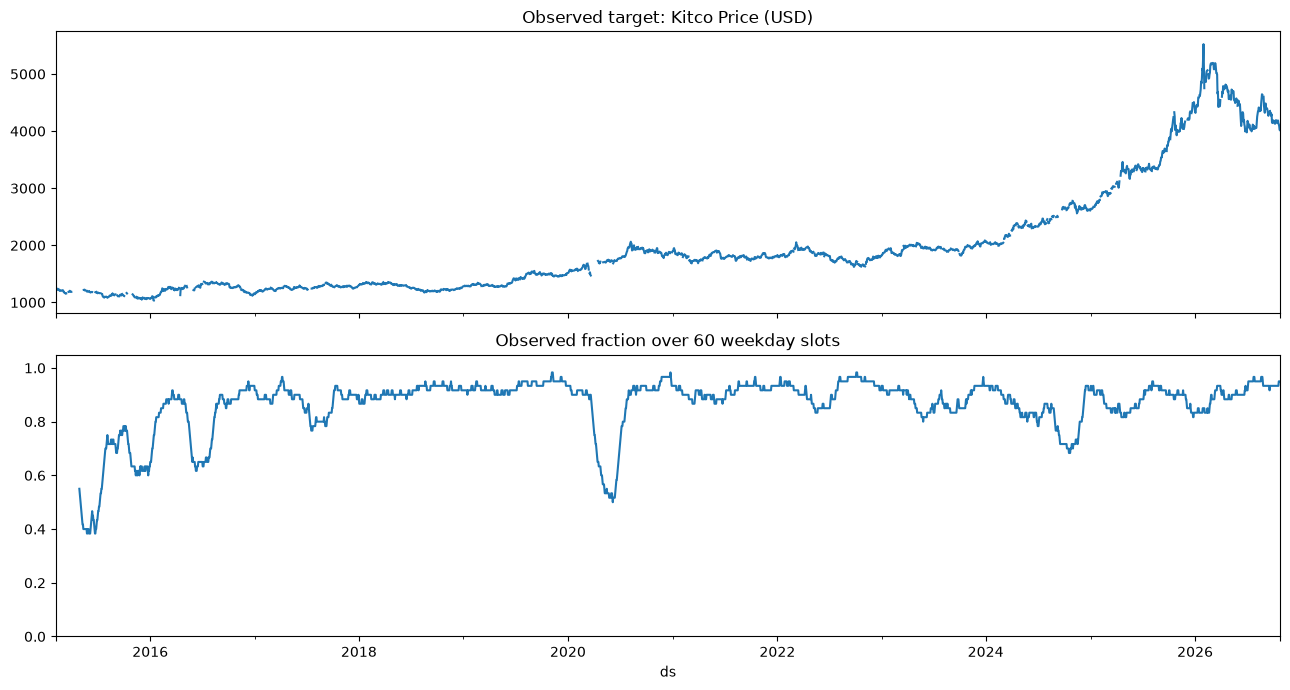

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
# Visual target coverage and the most-missing candidate features.
panel.y.plot(ax=axes[0], title=f"Observed target: {cfg['target_name']}")
panel.target_observed.rolling(60).mean().plot(ax=axes[1], title='Observed fraction over 60 weekday slots')
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
display(features.tail())
display(features.isna().mean().sort_values(ascending=False).head(15).rename('missing_fraction'))

## 5. Check causality by truncating history
Appending future rows must not change any already constructed feature.
Training-fitted scaling, imputation and model selection happen in the model notebooks.

In [6]:
from gold_common_utils import make_features
cut = len(panel) - cfg['holdout_steps']
# Truncate history and confirm earlier feature values are unchanged.
prefix_features = make_features(panel.iloc[:cut], cfg)
pd.testing.assert_frame_equal(prefix_features, features.iloc[:cut])
print('Causal feature prefix check passed.')

Causal feature prefix check passed.


## 6. Review cross-validation and holdout boundaries
Each outer fold selects its parameters using an earlier inner validation block.
The final holdout is excluded from tuning. Forecast origins are spaced by `origin_stride`.
A 20-step spacing reduces overlap for the longest initial horizon.

In [7]:
folds = make_folds(panel.index, cfg)
# Review the evaluation boundaries before running the model notebooks.
fold_view = folds.copy()
fold_view['train_through'] = [panel.index[i] for i in folds.cutoff]
fold_view['evaluate_through'] = [panel.index[i] for i in folds.stop]
display(fold_view)
print('Saved panel, candidates, feature dictionary, audits, assumptions and folds in data/processed/.')

,fold,cutoff,stop,train_through,evaluate_through
0,cv_1,2175,2301,2023-06-08,2023-12-01
1,cv_2,2301,2427,2023-12-01,2024-05-27
2,cv_3,2427,2553,2024-05-27,2024-11-19
3,cv_4,2553,2679,2024-11-19,2025-05-14
4,cv_5,2679,2805,2025-05-14,2025-11-06
5,holdout,2805,3057,2025-11-06,2026-10-26


Saved panel, candidates, feature dictionary, audits, assumptions and folds in data/processed/.
